$$
\begin{array}{c}
{\Huge \text{CAUSAL INFERENCE LAB 9}}\\
{\Large \textbf{Abhishek Bakshi}} \\
{\large \textit{Center for Data Science, New York University}} \\\\
{\Large \text{Office Hours: Wednesdays, 12:30 - 1:30 pm}} \\
{\Large \textit{Room 242, 60 5th Ave, 2nd floor}} \\\\
\text{Materials prepared by: Abhishek Bakshi, Xiang Gao}
\end{array}
$$

---

<h1 style="font-size: 42px;">Inexact Matching and Instrumental Variables</h1>

---

<h1 style="font-size: 30px;">Today's Goals:</h1>

<ol style="font-size: 20px; line-height: 1.6;">
  <li>Nearest-neighbor matching</li>
  <li>Matching on several controls</li>
  <li>Instrumental variables: the judge design</li>
  <li>Exogeneity and relevance</li>
  <li>Compliers and the LATE</li>
  <li>When the assumptions fail</li>
</ol>

---

<style>
body,
.jp-RenderedHTMLCommon,
.jp-RenderedMarkdown,
.markdown-body,
.vscode-body {
  font-family: Arial, Helvetica, sans-serif !important;
}
p, li, blockquote, td, th {
  font-size: 20px !important;
  line-height: 1.6 !important;
}
h1 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 42px !important;
  line-height: 1.25 !important;
  margin-top: 0.6em !important;
}
h2 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 30px !important;
  line-height: 1.3 !important;
  margin-top: 0.7em !important;
  border-bottom: 2px solid #469110;
  padding-bottom: 0.15em;
}
h3 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 25px !important;
  line-height: 1.35 !important;
  margin-top: 0.7em !important;
}
table { font-size: 19px !important; line-height: 1.45 !important; }
code, pre { font-size: 17px !important; }
blockquote { border-left: 5px solid #660033 !important; padding: 0.3em 0.8em !important; }
.MathJax, mjx-container { font-size: 115% !important; }
</style>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.precision", 3)
plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 19, "axes.labelsize": 16,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E6E3E4", "grid.linewidth": 0.8,
    "legend.frameon": False,
    "text.color": "#1F1418", "axes.titlecolor": "#1F1418", "axes.edgecolor": "#C7C4C5",
    "axes.labelcolor": "#625B5D", "xtick.labelcolor": "#625B5D", "ytick.labelcolor": "#625B5D",
    "xtick.color": "#C7C4C5", "ytick.color": "#C7C4C5",
    "figure.constrained_layout.use": True,
})
SEED = 107
# Every cell that draws random numbers makes its own generator from SEED,
# so re-running a cell gives the same numbers.


def robust(formula, data):
    """OLS with robust (HC0) standard errors."""
    return smf.ols(formula, data=data).fit(cov_type="HC0")


print("Ready: inexact matching and instrumental variables.")

Ready: inexact matching and instrumental variables.


## 1. Nearest-neighbor matching

---

The adoption example: $S=1$ if the parents are wealthy, $Y$ is the child's adult wealth, and

$$
S\perp U\mid \text{year of application}.
$$

The true effect is \$12,000.

In [2]:
def make_adoptions(n, rng):
    """Children matched to families in order of application, 1965 to 1968."""
    date = rng.uniform(0, 1460, n)                       # days after 1 January 1965
    cohort = (date // 365).astype(int)
    early = np.array([1, 0.3, 0.1, 0])[cohort]           # earlier batches had older applicants and children
    wealthy = rng.binomial(1, 0.2 + 0.6 * early)
    timing = 36 * early                                  # part of U: effect of the child's age at adoption
    child_wealth = 100 + 12 * wealthy + timing + rng.normal(0, 7, n)     # $000s
    return pd.DataFrame({"date": date, "year": 1965 + cohort, "wealthy": wealthy, "child_wealth": child_wealth})


adoptions = make_adoptions(800, np.random.default_rng(SEED + 71))
display(adoptions.sample(5, random_state=SEED).style.format("{:.2f}"))
display(adoptions.groupby("year")[["wealthy", "child_wealth"]].mean().style.format("{:.2f}"))

rows = []
for label, formula in [("No control", "child_wealth ~ wealthy"),
                       ("year as one number", "child_wealth ~ wealthy + year"),
                       ("An indicator for each year", "child_wealth ~ wealthy + C(year)")]:
    fit = smf.ols(formula, data=adoptions).fit(cov_type="HC0")
    rows.append({"Control": label, "Estimate ($000s)": fit.params["wealthy"], "Robust SE": fit.bse["wealthy"]})
display(pd.DataFrame(rows).style.format({"Estimate ($000s)": "{:.1f}", "Robust SE": "{:.1f}"}).hide(axis="index"))
print("True effect = 12.0")

,date,year,wealthy,child_wealth
550,454.92,1966.00,0.00,107.53
189,1358.98,1968.00,0.00,97.83
232,375.57,1966.00,1.00,115.85
248,1315.68,1968.00,0.00,99.08
518,1082.98,1967.00,0.00,99.28


,wealthy,child_wealth
year,,
1965,0.79,145.45
1966,0.34,115.32
1967,0.27,106.87
1968,0.16,101.82


Control,Estimate ($000s),Robust SE
No control,25.7,1.1
year as one number,14.7,0.7
An indicator for each year,11.9,0.6


True effect = 12.0


### A finer control

Now let $C$ = the exact application date. If only one family applied on 7 June 1966, and they were wealthy, there is nobody to compare them with on that date, so exact matching fails. **Nearest-neighbor matching** pairs each treated unit with the untreated unit whose control is closest and averages the differences over the $t$ treated units:

$$
\frac{1}{t}\sum_{i=1}^{t}\left(Y_{i_t}(S=1,U)-Y_{i_u}(S=0,U)\right).
$$

The closer the matches, the less bias we expect.

### Question 1: predict before running

1. What is expected to happen to the distance between matches as the sample grows?
2. Why would a far-away neighbor create bias even if $S\perp U\mid C$ holds?

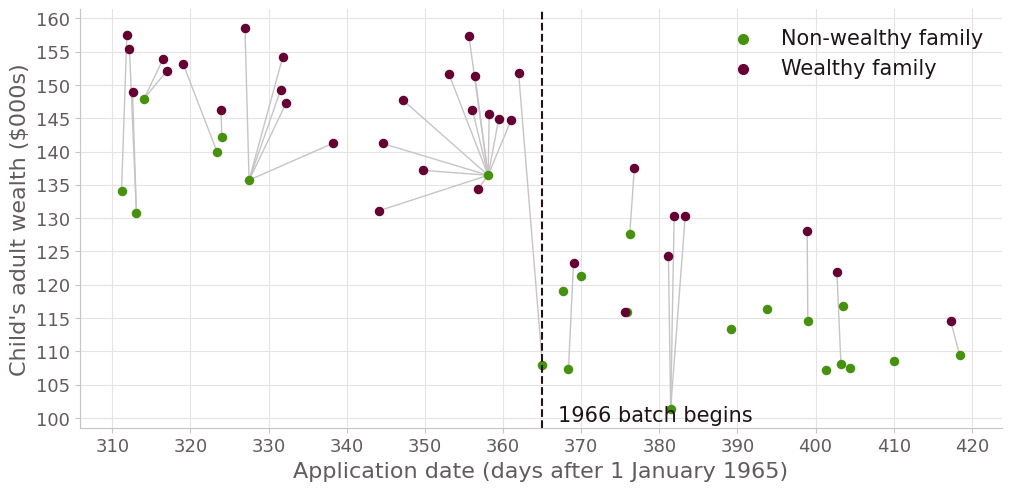

Nearest-neighbor estimate: 12.2; true effect = 12.0
Average distance between matches: 2.5 days


In [3]:
def nearest_neighbor_pairs(data):
    """For each wealthy family, the non-wealthy family with the closest application date."""
    treated, untreated = data[data.wealthy == 1], data[data.wealthy == 0]
    days_apart = np.abs(treated.date.to_numpy()[:, None] - untreated.date.to_numpy())
    nearest = untreated.iloc[days_apart.argmin(axis=1)]
    return pd.DataFrame({"treated_date": treated.date.to_numpy(), "treated_wealth": treated.child_wealth.to_numpy(),
                         "match_date": nearest.date.to_numpy(), "match_wealth": nearest.child_wealth.to_numpy()})


pairs = nearest_neighbor_pairs(adoptions)
window = pairs[pairs.treated_date.between(310, 420)]
non_wealthy = adoptions[(adoptions.wealthy == 0) & adoptions.date.between(310, 420)]   # matched or not

fig, ax = plt.subplots(figsize=(10, 4.8))
for _, row in window.iterrows():
    ax.plot([row.treated_date, row.match_date], [row.treated_wealth, row.match_wealth], color="#C7C4C5", lw=1, zorder=1)
ax.scatter(non_wealthy.date, non_wealthy.child_wealth, s=34, color="#469110", zorder=2, label="Non-wealthy family")
ax.scatter(window.treated_date, window.treated_wealth, s=34, color="#660033", zorder=3, label="Wealthy family")
ax.set_xticks(range(310, 421, 10))          # a tick (and gridline) every 10 days
ax.set_yticks(range(100, 161, 5))           # and every $5,000
ax.axvline(365, color="#1F1418", ls="--", lw=1.5)
ax.text(367, ax.get_ylim()[0] + 1, "1966 batch begins", color="#1F1418")
ax.set(xlabel="Application date (days after 1 January 1965)", ylabel="Child's adult wealth ($000s)")
ax.legend(loc="upper right", markerscale=1.2)
plt.show()

print(f"Nearest-neighbor estimate: {(pairs.treated_wealth - pairs.match_wealth).mean():.1f}; true effect = 12.0")
print(f"Average distance between matches: {(pairs.treated_date - pairs.match_date).abs().mean():.1f} days")

Larger samples usually mean more precise estimates. With inexact matching, they also mean closer matches and less bias, so sample size becomes an identification issue. Let's check.

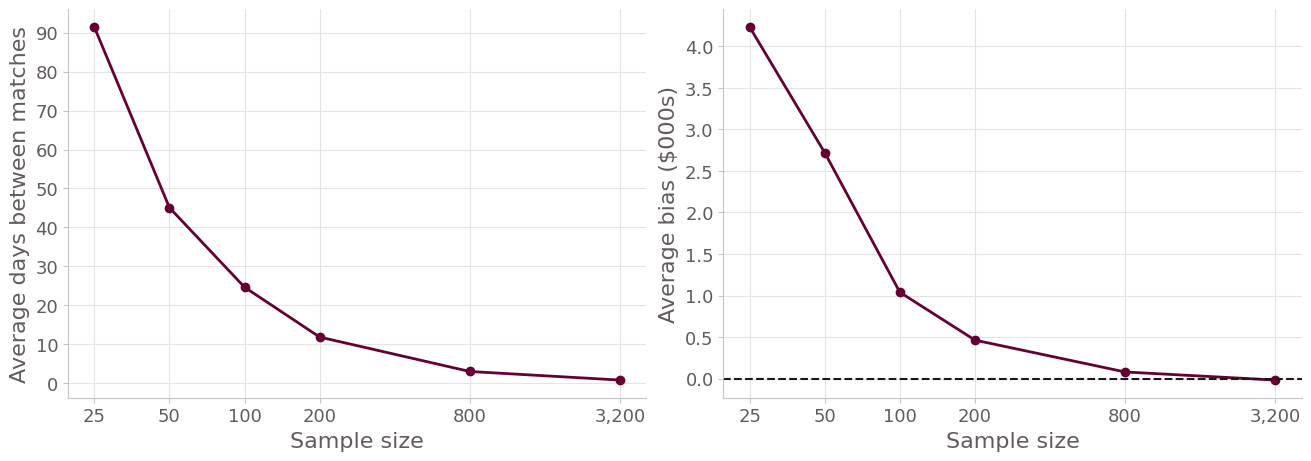

Sample size,Days apart,Bias
25,91.5,+4.23
50,45.1,+2.72
100,24.6,+1.04
200,11.8,+0.46
800,2.9,+0.08
3200,0.7,-0.02


In [4]:
sim_rng = np.random.default_rng(SEED + 8)
rows = []
for n, reps in [(25, 400), (50, 400), (100, 400), (200, 400), (800, 200), (3200, 50)]:
    estimates, distances = [], []
    for _ in range(reps):
        p = nearest_neighbor_pairs(make_adoptions(n, sim_rng))
        estimates.append((p.treated_wealth - p.match_wealth).mean())
        distances.append((p.treated_date - p.match_date).abs().mean())
    rows.append({"Sample size": n, "Days apart": np.mean(distances), "Bias": np.mean(estimates) - 12})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
axes[0].plot(sweep["Sample size"], sweep["Days apart"], "o-", color="#660033", lw=2)
axes[0].set(xscale="log", xlabel="Sample size", ylabel="Average days between matches")
axes[1].plot(sweep["Sample size"], sweep["Bias"], "o-", color="#660033", lw=2)
axes[1].axhline(0, color="#1F1418", ls="--", lw=1.5)
axes[1].set(xscale="log", xlabel="Sample size", ylabel="Average bias ($000s)")
axes[1].set_xticks([25, 50, 100, 200, 800, 3200], ["25", "50", "100", "200", "800", "3,200"])
axes[1].minorticks_off()
axes[0].set_yticks(range(0, 91, 10))
axes[1].set_yticks(np.arange(0, 4.5, 0.5))
plt.show()
display(sweep.style.format({"Days apart": "{:.1f}", "Bias": "{:+.2f}"}).hide(axis="index"))

### More than one control

With one control, the distance is just days apart. With several, we need one distance for the whole list, for example the straight-line distance once every control is put on a 0-to-1 scale. Choosing that scale is already a judgement call.

Below, 800 families are described by 1, 2, 4 or 8 such controls. For each wealthy family we find the nearest non-wealthy family. Who is wealthy is random here: we only look at distances.

### Question 2: predict before running

1. Suppose a good match must be within 0.05 of the wealthy family on every control. Roughly what share of families would qualify with 1 control? With 2?
2. With 8 controls, how much closer than a typical family will the nearest match be? What does that mean for the bias we saw above?

In [5]:
rng = np.random.default_rng(SEED + 42)
n = 800
controls = rng.uniform(0, 1, size=(n, 8))      # eight controls, each on a 0-to-1 scale
wealthy = rng.binomial(1, 0.4, n) == 1

rows = []
for k in [1, 2, 4, 8]:
    X = controls[:, :k]                         # use the first k controls
    distance = np.sqrt(((X[wealthy][:, None, :] - X[~wealthy][None, :, :]) ** 2).sum(axis=2))
    nearest = distance.min(axis=1)              # each wealthy family's nearest non-wealthy family
    rows.append({"Controls": k, "Distance to the nearest match": nearest.mean(),
                 "Distance to a typical non-wealthy family": distance.mean(),
                 "Matches closer than 0.05": (nearest < 0.05).mean()})
display(pd.DataFrame(rows).style.format({"Distance to the nearest match": "{:.3f}",
                                         "Distance to a typical non-wealthy family": "{:.2f}",
                                         "Matches closer than 0.05": "{:.0%}"}).hide(axis="index"))

Controls,Distance to the nearest match,Distance to a typical non-wealthy family,Matches closer than 0.05
1,0.001,0.33,100%
2,0.024,0.52,98%
4,0.138,0.78,1%
8,0.425,1.13,0%


## 2. Instrumental variables

---

Sometimes it is hard/impossible to find a control $C$ such that $S \perp U \mid C$. An **instrument** $Z$ is a third variable that

- affects $S$,
- affects $Y$ only through its effect on $S$, and
- unlike $S$, is independent of $U$.

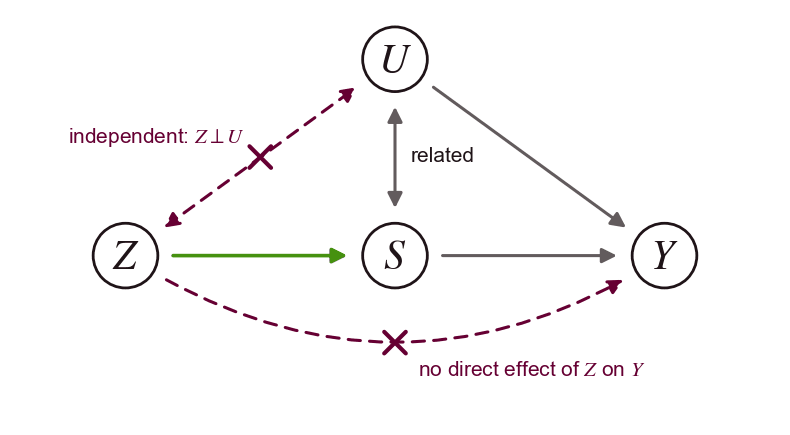

The part of the variation in $S$ that comes from $Z$ is then independent of $U$, and we use only that part.

### The judge example

We want the effect of prison on recidivism (relapsing into criminal activity after conviction):

- $Y=1$ if they commit another crime, 0 if not
- $S=1$ if they go to prison, 0 if not
- $Z=1$ if the mean judge sees the case, 0 if the nice judge does

Our town has two judges, a nice one and a mean one, who work different days. A case goes to whichever judge sits on the day it comes to trial.

### Question 3

1. Give two reasons why people sent to prison might re-offend more often for reasons other than prison.
2. What has to be true about how cases reach the two judges?

## 3. A town with two judges

---

For now, let's assume a world where there are only three kinds of crime - murder, littering and shoplifting. **Both judges send murderers to prison, neither sends litterers, and only the mean judge sends shoplifters.**

- Without prison, 55% of murderers, 40% of shoplifters and 15% of litterers would re-offend within five years, plus 10 points for people from the east side, where there are fewer jobs.
- Prison lowers re-offending by 30 points for murderers and 10 points for shoplifters. It makes no difference for litterers.
- Background columns: prior convictions (more for murderers), the east side, and minority status.

Each person's **criminality** (murderer, shoplifter or litterer) is hidden from the researcher. It stands for everything about a person that drives both the sentence and re-offending. Given the risk, whether someone re-offends also depends on **luck**, which is hidden too.

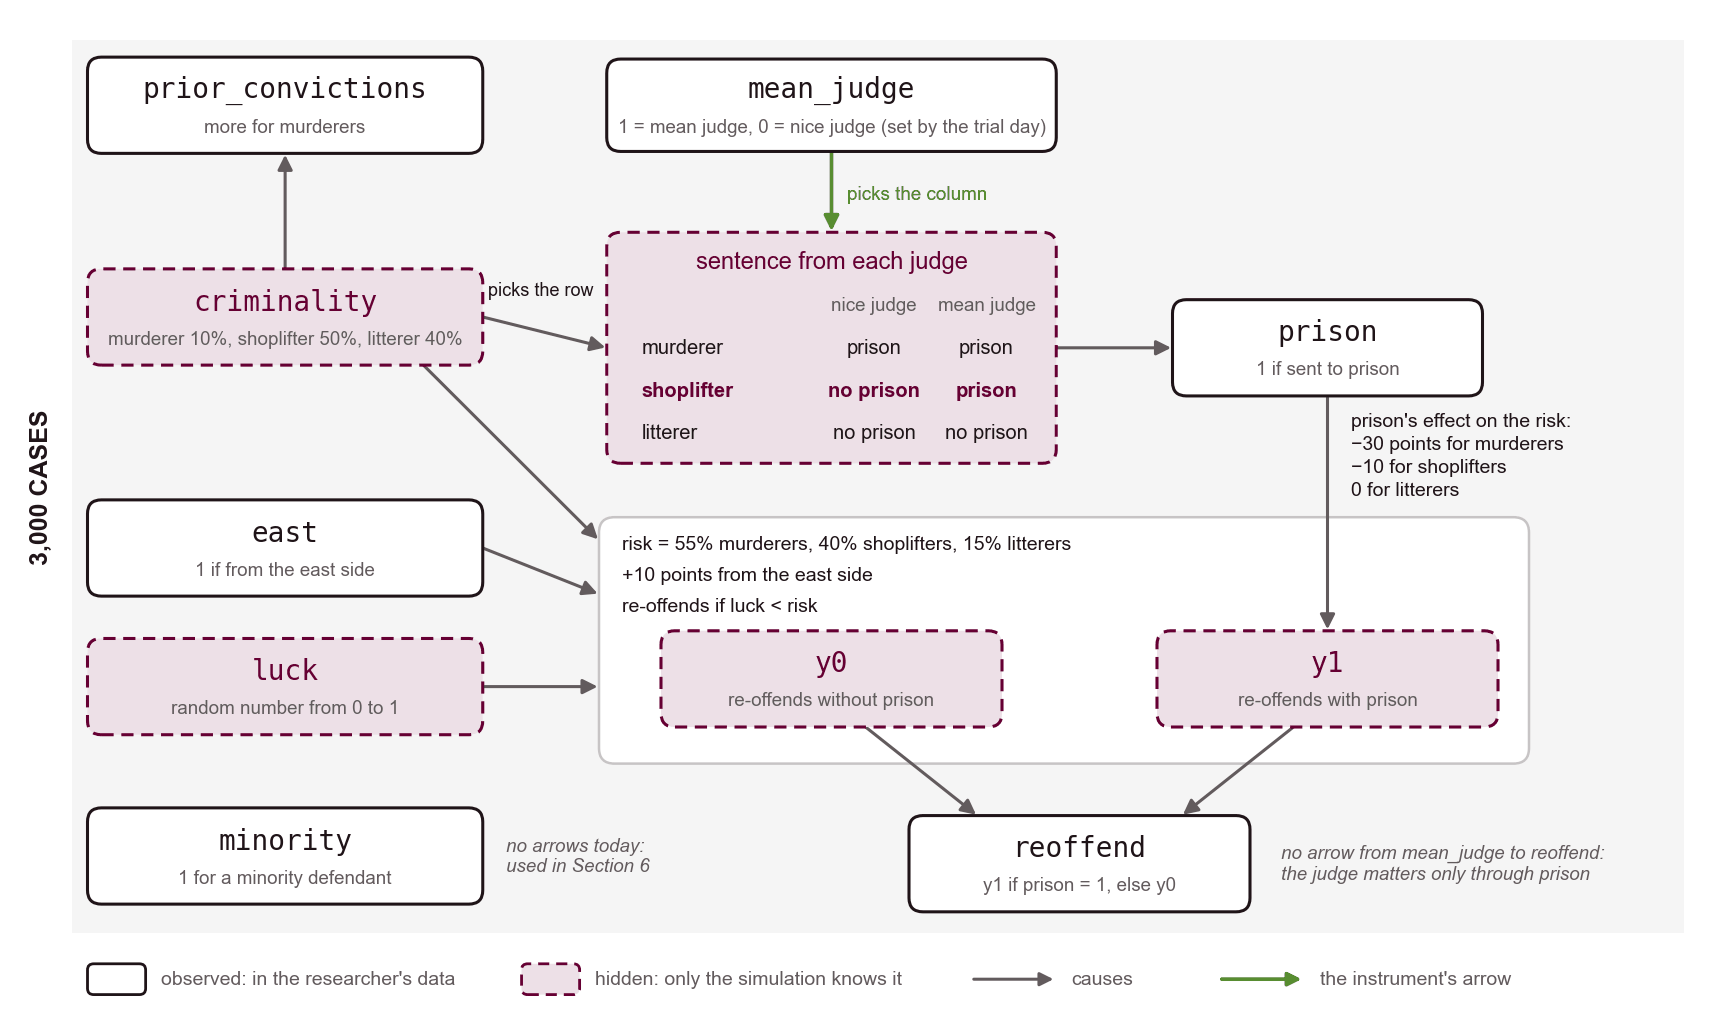

In [6]:
def make_cases(n, rng, mean_judge_east=0.5, mean_judge_west=0.5, fines=False, biased_nice_judge=False):
    """Criminal cases in a town with two judges. Section 6 changes the last four arguments."""
    # Background
    criminality = rng.choice(["murderer", "shoplifter", "litterer"], size=n, p=[0.10, 0.50, 0.40])   # UNOBSERVED
    murderer, shoplifter = criminality == "murderer", criminality == "shoplifter"
    east = rng.binomial(1, 0.5, n)                       # 1 if from the east side
    minority = rng.binomial(1, 0.4, n)
    prior_convictions = rng.poisson(np.select([murderer, shoplifter], [2.0, 1.0], 0.5))

    # Z: which judge sits on the day of trial (1 = mean judge, 0 = nice judge)
    day = rng.uniform(0, 1, n)
    mean_judge = (day < np.where(east == 1, mean_judge_east, mean_judge_west)).astype(int)

    # The sentence each judge would give: S(Z=0, V) and S(Z=1, V)
    prison_by_nice_judge = murderer.astype(int)                    # UNOBSERVED
    prison_by_mean_judge = (murderer | shoplifter).astype(int)     # UNOBSERVED
    if biased_nice_judge:   # Section 6: the nice judge jails minority shoplifters; the mean judge doesn't
        minority_shoplifter = shoplifter & (minority == 1)
        prison_by_nice_judge = np.where(minority_shoplifter, 1, prison_by_nice_judge)
        prison_by_mean_judge = np.where(minority_shoplifter, 0, prison_by_mean_judge)
    prison = np.where(mean_judge == 1, prison_by_mean_judge, prison_by_nice_judge)

    # Re-offending within five years, without prison (y0) and with prison (y1)
    risk = np.select([murderer, shoplifter], [0.55, 0.40], 0.15) + 0.10 * east
    prison_effect = np.select([murderer, shoplifter], [-0.30, -0.10], 0.0)
    luck = rng.uniform(0, 1, n)                                    # UNOBSERVED
    y0 = (luck < risk).astype(int)                                 # UNOBSERVED
    y1 = (luck < risk + prison_effect).astype(int)                 # UNOBSERVED
    reoffend = np.where(prison == 1, y1, y0)                       # only one outcome is ever seen
    if fines:   # Section 6: the mean judge also fines everyone not sent to prison (+10 points)
        fined = (mean_judge == 1) & (prison == 0)
        reoffend = np.where(fined, (luck < risk + 0.10).astype(int), reoffend)

    return pd.DataFrame({
        "east": east, "minority": minority, "prior_convictions": prior_convictions,
        "mean_judge": mean_judge, "prison": prison, "reoffend": reoffend,
        # columns no researcher would ever see:
        "criminality": criminality, "prison_by_nice_judge": prison_by_nice_judge,
        "prison_by_mean_judge": prison_by_mean_judge, "y0": y0, "y1": y1,
    })


HIDDEN = ["criminality", "prison_by_nice_judge", "prison_by_mean_judge", "y0", "y1"]

cases = make_cases(3_000, np.random.default_rng(SEED + 390))
observed = cases.drop(columns=HIDDEN)
print(f"{len(cases):,} cases; the mean judge heard {cases.mean_judge.sum():,} of them")
observed.sample(5, random_state=SEED)

3,000 cases; the mean judge heard 1,515 of them


,east,minority,prior_convictions,mean_judge,prison,reoffend
2183,1,1,0,0,0,0
318,1,0,1,1,1,0
73,0,0,1,0,0,0
2758,1,0,2,1,1,0
2155,1,1,0,0,0,0


### Question 4: predict before running

1. Will people sent to prison re-offend more or less often than people who were not?
2. Is that difference the effect of prison?

In [7]:
raw = robust("reoffend ~ prison", observed)
low, high = raw.conf_int().loc["prison"]
print(f"Re-offended: {observed[observed.prison == 1].reoffend.mean():.1%} of those sent to prison, "
      f"{observed[observed.prison == 0].reoffend.mean():.1%} of the rest")
print(f"Raw difference: {100 * raw.params['prison']:+.1f} points (95% CI {100 * low:+.1f} to {100 * high:+.1f})")

# The same cases by criminality, using the hidden columns
cases["effect_of_prison"] = cases.y1 - cases.y0
by_criminality = cases.groupby("criminality")[["prison", "reoffend", "effect_of_prison"]].mean()
by_criminality["share_of_cases"] = cases.criminality.value_counts(normalize=True)
by_criminality.loc[["murderer", "shoplifter", "litterer"]]

Re-offended: 33.6% of those sent to prison, 29.6% of the rest
Raw difference: +4.0 points (95% CI +0.5 to +7.5)


,prison,reoffend,effect_of_prison,share_of_cases
criminality,,,,
murderer,1.000,0.301,-0.287,0.096
shoplifter,0.509,0.399,-0.105,0.506
litterer,0.000,0.199,0.000,0.398


## 4. The judge as an instrument

---

Just as $Y(S,U)$ is re-offending given the sentence $S$ and everything else $U$, write the sentence as $S(Z,V)$: it depends on the judge $Z$ and on everything else, $V$. IV identifies the local average treatment effect (LATE) under three assumptions:

- **Instrument exogeneity:** $U,V\perp Z$
- **Instrument relevance:** $S(Z=1,V)\neq S(Z=0,V)$ sometimes
- **Monotonicity:** $S(Z=1,V)\geq S(Z=0,V)$ always

$Z$ does not appear in $Y(S,U)$: the judge has no direct effect on re-offending. This section looks at exogeneity and relevance, and Section 5 at monotonicity.

Exogeneity can't be proven from data. But if judges really are assigned by the day, the background columns should look the same for both judges.

### Question 5:

1. For this example, how do we state relevance and monotonicity in words?
2. What should the balance table show?

In [8]:
balance = observed.groupby("mean_judge")[["east", "minority", "prior_convictions"]].mean().T
balance.columns = ["Nice judge", "Mean judge"]
balance["p-value"] = [robust(f"{column} ~ mean_judge", observed).pvalues["mean_judge"] for column in balance.index]
balance

,Nice judge,Mean judge,p-value
east,0.491,0.496,0.765
minority,0.403,0.401,0.910
prior_convictions,0.937,0.896,0.283


If the judge is exogenous, getting the mean judge is itself a natural experiment, so we can estimate its effects directly: on prison, which is relevance, and on re-offending. We don't really care about judges, though. We care about prison.

### Question 6: predict before running

1. How much more often will the mean judge's cases go to prison?
2. Will the mean judge's cases re-offend more or less often?

In [9]:
first_stage = robust("prison ~ mean_judge", observed)
judge_effect = robust("reoffend ~ mean_judge", observed)
for name, fit in [("Prison", first_stage), ("Re-offending", judge_effect)]:
    low, high = fit.conf_int().loc["mean_judge"]
    print(f"{name}, mean judge minus nice judge: {100 * fit.params['mean_judge']:+.1f} points "
          f"(95% CI {100 * low:+.1f} to {100 * high:+.1f})")

Prison, mean judge minus nice judge: +49.1 points (95% CI +46.2 to +52.0)
Re-offending, mean judge minus nice judge: -5.8 points (95% CI -9.1 to -2.4)


### Experiments as instruments

The same logic works when an experiment can only assign something small. We can't randomly send people to college, but we could randomly offer scholarships ($Z$) and use them to learn how college attendance ($S$) affects wages ($Y$). Some students offered a scholarship won't go to college, and some who aren't offered one will go anyway.

### Question 7

1. Which assumptions does randomizing the offer guarantee? Which could still fail, and how?
2. Comparing the wages of students who were and weren't offered a scholarship: what effect does that measure?

## 5. Who does the judge move?

---

Each person has two potential sentences: $S(Z=0,V)$ from the nice judge and $S(Z=1,V)$ from the mean judge. The pair defines four types:

- **Always-taker:** $S(Z=0,V)=1$ and $S(Z=1,V)=1$
- **Never-taker:** $S(Z=0,V)=0$ and $S(Z=1,V)=0$
- **Complier:** $S(Z=0,V)=0$ and $S(Z=1,V)=1$
- **Defier:** $S(Z=0,V)=1$ and $S(Z=1,V)=0$

In this language, relevance is $P(\text{Complier})>0$ and monotonicity is $P(\text{Defier})=0$.

### Question 8

1. In our town, which kind of crime makes each type?
2. For which type can the judge tell us anything about the effect of prison?

In [10]:
by_nice = cases.prison_by_nice_judge     # S(Z=0, V), hidden
by_mean = cases.prison_by_mean_judge     # S(Z=1, V), hidden

cases["type"] = "Defier"                 # changed below unless by_nice == 1 and by_mean == 0
cases.loc[(by_nice == 1) & (by_mean == 1), "type"] = "Always-taker"
cases.loc[(by_nice == 0) & (by_mean == 0), "type"] = "Never-taker"
cases.loc[(by_nice == 0) & (by_mean == 1), "type"] = "Complier"

pd.crosstab(cases.criminality, cases.type).loc[["murderer", "shoplifter", "litterer"]]

type,Always-taker,Complier,Never-taker
criminality,,,
murderer,289,0,0
shoplifter,0,1518,0
litterer,0,0,1193


In real data we never see both sentences for the same person, so we can't tell who is a complier. Under monotonicity we can still count each type. Anyone the nice judge jails would also be jailed by the mean judge, so they are always-takers; anyone the mean judge lets go is a never-taker:

$$
P(\text{Always-taker})=P(S=1\mid Z=0),\qquad P(\text{Never-taker})=P(S=0\mid Z=1),
$$

and the compliers are the rest: $P(S=1\mid Z=1)-P(S=1\mid Z=0)$, the judge's effect on prison.

In [11]:
p_always = observed[observed.mean_judge == 0].prison.mean()        # P(S=1 | Z=0)
p_never = 1 - observed[observed.mean_judge == 1].prison.mean()     # P(S=0 | Z=1)
p_complier = 1 - p_always - p_never
print(f"From the data: always-takers {p_always:.1%}, never-takers {p_never:.1%}, compliers {p_complier:.1%}")

true_share = cases.type.value_counts(normalize=True)
print(f"True (hidden): always-takers {true_share['Always-taker']:.1%}, never-takers {true_share['Never-taker']:.1%}, "
      f"compliers {true_share['Complier']:.1%}")

From the data: always-takers 10.6%, never-takers 40.3%, compliers 49.1%
True (hidden): always-takers 9.6%, never-takers 39.8%, compliers 50.6%


### The local average treatment effect

Only compliers' sentences depend on the judge, so a difference between the two judges' cases can only come from compliers. The LATE is the average effect of prison among them:

$$
\text{LATE}=\mathbb E[Y(S=1,U)-Y(S=0,U)\mid \text{Complier}].
$$

The simulation lets us compare the two judges' cases separately for murderers, shoplifters and litterers.

### Question 9: predict before running

1. For which crime will the mean judge's cases re-offend at a different rate?
2. By roughly how much?

In [12]:
gaps = cases.groupby(["criminality", "mean_judge"]).reoffend.mean().unstack()
gaps.columns = ["Nice judge", "Mean judge"]
gaps["Difference"] = gaps["Mean judge"] - gaps["Nice judge"]
gaps["Cases"] = cases.criminality.value_counts()
gaps.loc[["murderer", "shoplifter", "litterer"]]

,Nice judge,Mean judge,Difference,Cases
criminality,,,,
murderer,0.293,0.311,0.018,289
shoplifter,0.450,0.348,-0.102,1518
litterer,0.208,0.190,-0.018,1193


A LATE is only interesting if we care about the people the instrument moves.

### Question 10

1. Will the LATE equal the average effect of prison over everyone?
2. Do we care about shoplifters?

In [13]:
effect = cases.effect_of_prison          # y1 - y0 for each person (hidden)
print(f"Compliers (shoplifters), the LATE: {100 * effect[cases.type == 'Complier'].mean():+.1f} points")
print(f"Everyone, the ATE:                 {100 * effect.mean():+.1f} points")
print(f"Those sent to prison:              {100 * effect[cases.prison == 1].mean():+.1f} points")
print(f"Raw comparison from Section 3:     {100 * raw.params['prison']:+.1f} points")

Compliers (shoplifters), the LATE: -10.5 points
Everyone, the ATE:                 -8.1 points
Those sent to prison:              -15.3 points
Raw comparison from Section 3:     +4.0 points


## 6. When the assumptions fail

---

Same 3,000 cases, same draws. Each scenario below changes one thing about the court.

### One judge per side of town

The mean judge now sits in the east-side courthouse and hears 80% of east-side cases but only 20% of west-side cases.

### Question 11: predict before running

1. Which assumption fails?
2. Will the balance table show it?

In [14]:
by_side = make_cases(3_000, np.random.default_rng(SEED + 390), mean_judge_east=0.8, mean_judge_west=0.2)

balance = by_side.groupby("mean_judge")[["east", "minority", "prior_convictions"]].mean().T
balance.columns = ["Nice judge", "Mean judge"]
balance["p-value"] = [robust(f"{column} ~ mean_judge", by_side).pvalues["mean_judge"] for column in balance.index]
display(balance)

judge_effect_now = robust("reoffend ~ mean_judge", by_side).params["mean_judge"]
print(f"Re-offending, mean judge minus nice judge: {100 * judge_effect_now:+.1f} points "
      f"(was {100 * judge_effect.params['mean_judge']:+.1f})")

gaps = by_side.groupby(["criminality", "mean_judge"]).reoffend.mean().unstack()
gaps.columns = ["Nice judge", "Mean judge"]
gaps["Difference"] = gaps["Mean judge"] - gaps["Nice judge"]
gaps.loc[["murderer", "shoplifter", "litterer"]]

,Nice judge,Mean judge,p-value
east,0.20,0.789,0.000
minority,0.40,0.403,0.875
prior_convictions,0.94,0.892,0.218


Re-offending, mean judge minus nice judge: +0.5 points (was -5.8)


,Nice judge,Mean judge,Difference
criminality,,,
murderer,0.272,0.331,0.059
shoplifter,0.427,0.378,-0.050
litterer,0.169,0.229,0.060


### Fines

Judges are back to working different days. Now the mean judge also hands heavy fines to everyone not sent to prison, and the fines push some of them back into crime (+10 points). Sentences don't change.

### Question 12: predict before running

1. Which assumption fails?
2. Will the balance table show it?

In [15]:
fined = make_cases(3_000, np.random.default_rng(SEED + 390), fines=True)

balance = fined.groupby("mean_judge")[["east", "minority", "prior_convictions"]].mean().T
balance.columns = ["Nice judge", "Mean judge"]
balance["p-value"] = [robust(f"{column} ~ mean_judge", fined).pvalues["mean_judge"] for column in balance.index]
display(balance)

judge_effect_now = robust("reoffend ~ mean_judge", fined).params["mean_judge"]
print(f"Re-offending, mean judge minus nice judge: {100 * judge_effect_now:+.1f} points "
      f"(was {100 * judge_effect.params['mean_judge']:+.1f})")

gaps = fined.groupby(["criminality", "mean_judge"]).reoffend.mean().unstack()
gaps.columns = ["Nice judge", "Mean judge"]
gaps["Difference"] = gaps["Mean judge"] - gaps["Nice judge"]
gaps.loc[["murderer", "shoplifter", "litterer"]]

,Nice judge,Mean judge,p-value
east,0.491,0.496,0.765
minority,0.403,0.401,0.910
prior_convictions,0.937,0.896,0.283


Re-offending, mean judge minus nice judge: -1.7 points (was -5.8)


,Nice judge,Mean judge,Difference
criminality,,,
murderer,0.293,0.311,0.018
shoplifter,0.450,0.348,-0.102
litterer,0.208,0.290,0.082


### A nice judge who isn't nice to everyone

Now say the nice judge is nice to white defendants but racist against minorities: the nice judge jails minority shoplifters, whom the mean judge lets go.

### Question 13: predict before running

1. Who are the defiers now?
2. Will the mean judge still send more people to prison overall?
3. Will counting always-takers from the data, $P(S=1\mid Z=0)$, still give the right share?

In [16]:
biased = make_cases(3_000, np.random.default_rng(SEED + 390), biased_nice_judge=True)

prison_rates = biased.groupby(["minority", "mean_judge"]).prison.mean().unstack()
prison_rates.columns = ["Nice judge", "Mean judge"]
prison_rates.index = ["White", "Minority"]
prison_rates["Difference"] = prison_rates["Mean judge"] - prison_rates["Nice judge"]
display(prison_rates)
first_stage_now = robust("prison ~ mean_judge", biased).params["mean_judge"]
print(f"Prison, mean judge minus nice judge, all defendants: {100 * first_stage_now:+.1f} points")

counted = biased[biased.mean_judge == 0].prison.mean()            # P(S=1 | Z=0)
by_nice, by_mean = biased.prison_by_nice_judge, biased.prison_by_mean_judge
print(f"Always-takers counted from the data: {counted:.1%}")
print(f"True shares (hidden): always-takers {((by_nice == 1) & (by_mean == 1)).mean():.1%}, "
      f"defiers {((by_nice == 1) & (by_mean == 0)).mean():.1%}")

,Nice judge,Mean judge,Difference
White,0.105,0.604,0.499
Minority,0.592,0.096,-0.496


Prison, mean judge minus nice judge, all defendants: +9.9 points
Always-takers counted from the data: 30.1%
True shares (hidden): always-takers 9.6%, defiers 19.6%
